[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/17_lakehouse.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 17 of 21*

# Lakehouse & Table Formats

Database features on cheap files: why plain lakes break, how Iceberg and Delta use snapshots and manifests, ACID on object storage, time travel, MERGE, copy-on-write vs merge-on-read, compaction and clustering.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Files never change. A table is just a pointer to the list of files that count right now, and swapping that pointer is the whole trick.

**What interviewers really test here:** How ACID works on object storage, copy-on-write vs merge-on-read, and compaction.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why plain data lakes break *(Basics)*
- [ ] 2. Updating immutable files *(Core)*
- [ ] 3. Keeping tables fast *(Core)*
- [ ] 4. Evolution, privacy and choosing a format *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Lake vs warehouse vs lakehouse

|   | Lake | Warehouse | Lakehouse |
| --- | --- | --- | --- |
| Storage | open files | managed by the vendor | open files + table format |
| ACID | no | yes | yes |
| Engines | many | one | many |
| Cost | low | higher | low storage, varied compute |

---
# Part 2: Lessons, step by step

## Lesson 1: Why plain data lakes break

*Level: Basics*

A folder of Parquet files is cheap, but it's missing what databases give you:



| Problem | What happens |
| --- | --- |
| No atomic writes | a reader sees half of a job's files |
| Two writers | they overwrite each other |
| No updates or deletes | you rewrite everything by hand |
| Listing files is slow | queries wait on millions of objects |
| Schema changes | old files break new readers |



**Table formats (Apache Iceberg, Delta Lake, Apache Hudi) add a metadata layer that says exactly which files make up the table.**



```text
Catalog → current metadata → snapshot → manifests → data files
                                 (a list of files, with min/max per column)
```



**The key trick is immutability.** Files never change. A write adds new files and creates a new **snapshot**, then atomically swaps one pointer. Readers see either the old version or the new one, never half.



| Commit | Snapshot's files |
| --- | --- |
| add f1 | f1 |
| add f2 | f1, f2 |
| add f3, remove f1 | f2, f3 |



**Time travel** comes free: old snapshots still point to old files, so you can query yesterday's table or roll back a bad load. At time 25, with commits at 10, 20 and 30, you read the snapshot from 20.



```python
SELECT * FROM orders FOR TIMESTAMP AS OF '2026-01-05 00:00:00';   -- Iceberg, in Spark SQL
spark.read.format("delta").option("versionAsOf", 12).load(path)    # Delta
```

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q5](#q5), [Q17](#q17), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 2: Updating immutable files

*Level: Core*

Files can't change, so how does UPDATE work?



|   | Copy-on-write | Merge-on-read |
| --- | --- | --- |
| Update | rewrite the whole file | write a small delta file |
| Writes | slower | fast |
| Reads | fast | slower: merge at read time |
| Suits | read-heavy tables | frequent updates, CDC |



**By hand.** Updating id 2 in a file holding ids 1 and 2 rewrites 2 rows to change 1. With 10 updates a day in files of 1,000 rows, copy-on-write rewrites 10,000 rows. With merge-on-read and 100 reads a day, readers merge 1,000 delta rows in total.



**MERGE INTO** does upserts and deletes in one atomic statement, which is why CDC to a lake became practical:



```python
MERGE INTO target t USING changes c ON t.id = c.id
WHEN MATCHED AND c.op = 'D' THEN DELETE
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *;
```



**Concurrent writers use optimistic concurrency.** Everyone assumes success, then tries to swap the pointer. If the table moved on, check for a real conflict. Two writers on d1 and d2 both succeed, and a second writer on d1 that read an old version conflicts and must retry.

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q7](#q7), [Q8](#q8), [Q9](#q9), [Q19](#q19), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 3: Keeping tables fast

*Level: Core*

**Metadata pruning.** Manifests store min and max per column for each file, so a query can pick files with no directory listing. Looking for 18 among files 1–10, 11–20 and 15–30 reads two of the three.



**Clustering makes that work.** If values are spread randomly, every file's range covers everything. For values 1, 9, 5, 2, 9, 7, 3, 9, 8 in files of 3, looking for 5 reads **3 files**. Sorted, it reads **1**. The chart measures this at a larger scale: with 100,000 random values in files of 1,000 rows, an unsorted lookup reads all 100 files, and a sorted one reads 1.



**Z-ordering** sorts on two columns at once, by interleaving their bits, so nearby points in both dimensions stay near each other on disk. It helps a little on each column, rather than perfectly on one.



**Maintenance is your job:**



| Task | Why | Example |
| --- | --- | --- |
| Compaction | merges small files | half the files under 128 MB is a signal |
| Expire snapshots | time travel keeps old files, costing money | keeping only time 30 frees a and b |
| Remove orphans | failed writes leave junk | skip very new files: a write may be in progress |



Bin-packing files 10, 20, 30, 90 with a 128 MB target gives 60 and 90, leaving large files alone.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

files read, unsorted: [100.  20.  10.]
files read, sorted:   [1. 1. 1.]


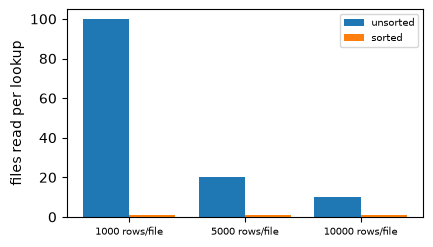

In [2]:
def clustering_chart():
    rng = np.random.default_rng(0)
    values = rng.integers(0, 100000, 100000)
    def files_read(data, file_rows):
        lows = [data[i:i + file_rows].min() for i in range(0, len(data), file_rows)]
        highs = [data[i:i + file_rows].max() for i in range(0, len(data), file_rows)]
        targets = rng.integers(0, 100000, 50)
        return np.mean([sum(a <= t <= b for a, b in zip(lows, highs)) for t in targets])
    sizes = [1000, 5000, 10000]
    unsorted = [files_read(values, s) for s in sizes]
    ordered = [files_read(np.sort(values), s) for s in sizes]
    print("files read, unsorted:", np.round(unsorted, 1))
    print("files read, sorted:  ", np.round(ordered, 1))
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    x = np.arange(3)
    ax.bar(x - 0.2, unsorted, 0.4, label="unsorted")
    ax.bar(x + 0.2, ordered, 0.4, label="sorted")
    ax.set_xticks(x, [f"{s} rows/file" for s in sizes], fontsize=7)
    ax.set_ylabel("files read per lookup")
    ax.legend(fontsize=7)


clustering_chart()

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q11](#q11), [Q20](#q20), [Q12](#q12), [Q3](#q3), [Q13](#q13), [Q1](#q1). Try one now, or carry on and do them in Part 3.

## Lesson 4: Evolution, privacy and choosing a format

*Level: Advanced*

**Hidden partitioning (Iceberg).** Users filter on the timestamp, and Iceberg works out the partition. A query from 10 February to 5 March scans the 2026-02 and 2026-03 partitions, and nobody has to remember a special column. You can also change the partition scheme later without rewriting old data.



**Safe schema evolution.** Files store column **ids**, not just names, so renaming is safe: id 1 can become "label" and still read old files, and a new column reads as None.



**Privacy on immutable files.** Deleting a user rewrites only the files holding them: 2 files and 3 other rows here. But **old snapshots still hold the data**, until you expire them, so deletion isn't finished after the DELETE statement. This trips many teams up.



|   | Iceberg | Delta Lake | Hudi |
| --- | --- | --- | --- |
| Strength | open, wide engine support, hidden partitioning | tight Spark and Databricks integration | record-level upserts, streaming ingestion |



They've converged a lot, and tools can increasingly read across formats. Choose by your engines and team, and check current features, since this area changes quickly.

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q15](#q15), [Q16](#q16). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Orphan Files

🟢 Warm-up · *Failed writes leave debris*

Return files on storage that no snapshot references, sorted. Don't delete files newer than a safety age, as a write may be in progress. Files are (name, age\_days).

**Examples**

- `storage = [('a', 10), ('b', 10), ('tmp', 10), ('new', 0)], referenced = ['a', 'b'], min_age = 3` → `['tmp']`

In [ ]:
def orphans(storage, referenced, min_age):
    """
    Return files on storage that no snapshot references, sorted. Don't delete
    files newer than a safety age, as a write may be in progress. Files are
    (name, age_days).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(orphans, [
    (([('a', 10), ('b', 10), ('tmp', 10), ('new', 0)], ['a', 'b'], 3), ['tmp']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def orphans(storage, referenced, min_age):
    out = []
    for name, age in storage:
        if name not in referenced and age >= min_age:
            out.append(name)
    return sorted(out)
```

**Cost:** O(f) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A set.

```python
def orphans(storage, referenced, min_age):
    used = set(referenced)
    return sorted(n for n, a in storage if n not in used and a >= min_age)
```

**Cost:** O(f) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(f) time and O(f) space."

"I can do better: A set. That's O(f) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/orphan-files)

<a id="q2"></a>
### Q2. Choose a Table Strategy

🟢 Warm-up · *COW, MOR or append*

Return 'append only' if there are no updates; 'copy-on-write' if reads are at least 10× the update batches per day; otherwise 'merge-on-read'.

**Examples**

- `updates = 0, reads = 100` → `'append only'`
- `updates = 5, reads = 100` → `'copy-on-write'`
- `updates = 100, reads = 100` → `'merge-on-read'`

In [ ]:
def table_strategy(updates, reads):
    """
    Return 'append only' if there are no updates; 'copy-on-write' if reads are
    at least 10× the update batches per day; otherwise 'merge-on-read'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(table_strategy, [
    ((0, 100), 'append only'),
    ((5, 100), 'copy-on-write'),
    ((100, 100), 'merge-on-read'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A conditional expression.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def table_strategy(updates, reads):
    if updates == 0:
        return "append only"
    if reads >= 10 * updates:
        return "copy-on-write"
    return "merge-on-read"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A conditional expression.

```python
def table_strategy(updates, reads):
    return "append only" if not updates else "copy-on-write" if reads >= 10 * updates else "merge-on-read"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(1) time and O(1) space."

"I can do better: A conditional expression. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/choose-a-table-strategy)

<a id="q3"></a>
### Q3. Does This Table Need Compaction?

🟢 Warm-up · *Measure small files*

Return (share of files under limit MB, average file MB), rounded to 2 decimals.

**Examples**

- `sizes = [10, 20, 500, 600], limit = 128` → `(0.5, 282.5)`

In [ ]:
def small_file_stats(sizes, limit):
    """
    Return (share of files under limit MB, average file MB), rounded to 2
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(small_file_stats, [
    (([10, 20, 500, 600], 128), (0.5, 282.5)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Generators.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def small_file_stats(sizes, limit):
    small = total = 0
    for s in sizes:
        total += s
        if s < limit:
            small += 1
    return (round(small / len(sizes), 2), round(total / len(sizes), 2))
```

**Cost:** O(f) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Generators.

```python
def small_file_stats(sizes, limit):
    return (round(sum(s < limit for s in sizes) / len(sizes), 2), round(sum(sizes) / len(sizes), 2))
```

**Cost:** O(f) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(f) time and O(1) space."

"I can do better: Generators. That's O(f) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/does-this-table-need-compaction)

<a id="q4"></a>
### Q4. Snapshot Commit

🟡 Interview standard · *ACID on files*

A snapshot is a list of data files. Commit adds and removes files, creating a new snapshot. Return the list of snapshots after each commit.

**Examples**

- `commits = [(['f1'], []), (['f2'], []), (['f3'], ['f1'])]` → `[['f1'], ['f1', 'f2'], ['f2', 'f3']]`

In [ ]:
def snapshots(commits):
    """
    A snapshot is a list of data files. Commit adds and removes files, creating
    a new snapshot. Return the list of snapshots after each commit.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(snapshots, [
    (([(['f1'], []), (['f2'], []), (['f3'], ['f1'])],), [['f1'], ['f1', 'f2'], ['f2', 'f3']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Copy and edit lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Sets.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Copy and edit lists.

```python
def snapshots(commits):
    current, out = [], []
    for add, remove in commits:
        new = [f for f in current if f not in remove] + add
        out.append(new)
        current = new
    return out
```

**Cost:** O(c·f) time, O(c·f) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Sets.

```python
def snapshots(commits):
    out, cur = [], set()
    for add, remove in commits:
        cur = (cur - set(remove)) | set(add)
        out.append(sorted(cur))
    return out
```

**Cost:** O(c·f) time, O(c·f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Copy and edit lists. That costs O(c·f) time and O(c·f) space."

"I can do better: Sets. That's O(c·f) time and O(c·f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/snapshot-commit)

<a id="q5"></a>
### Q5. Time Travel

🟡 Interview standard · *Query the past*

Snapshots are (commit\_time, files), sorted. Return files for the latest snapshot at or before t, or None.

**Examples**

- `snaps = [(10, ['a']), (20, ['a', 'b']), (30, ['c'])], t = 25` → `['a', 'b']`
- `snaps = [(10, ['a'])], t = 5` → `None`

In [ ]:
import bisect

def time_travel(snaps, t):
    """
    Snapshots are (commit_time, files), sorted. Return files for the latest
    snapshot at or before t, or None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(time_travel, [
    (([(10, ['a']), (20, ['a', 'b']), (30, ['c'])], 25), ['a', 'b']),
    (([(10, ['a'])], 5), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Binary search.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan.

```python
def time_travel(snaps, t):
    best = None
    for when, files in snaps:
        if when <= t:
            best = files
    return best
```

**Cost:** O(s) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Binary search.

```python
def time_travel(snaps, t):
    i = bisect.bisect_right([s[0] for s in snaps], t)
    return snaps[i - 1][1] if i else None
```

**Cost:** O(log s) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan. That costs O(s) time and O(1) space."

"I can do better: Binary search. That's O(log s) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/time-travel)

<a id="q6"></a>
### Q6. Copy-on-Write Update

🟡 Interview standard · *Rewrite the file*

Files map to rows {id: value}. To update one id, rewrite the whole file containing it. Return (new files, rows rewritten).

**Examples**

- `files = {'f1': {1: 'a', 2: 'b'}, 'f2': {3: 'c'}}, key = 2, value = 'B'` → `({'f1_v2': {1: 'a', 2: 'B'}, 'f2': {3: 'c'}}, 2)`

In [ ]:
def copy_on_write(files, key, value):
    """
    Files map to rows {id: value}. To update one id, rewrite the whole file
    containing it. Return (new files, rows rewritten).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(copy_on_write, [
    (({'f1': {1: 'a', 2: 'b'}, 'f2': {3: 'c'}}, 2, 'B'), ({'f1_v2': {1: 'a', 2: 'B'}, 'f2': {3: 'c'}}, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop through files.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop through files.

```python
def copy_on_write(files, key, value):
    out, rewritten = {}, 0
    for name, rows in files.items():
        if key in rows:
            new = dict(rows)
            new[key] = value
            out[name + "_v2"] = new
            rewritten += len(rows)
        else:
            out[name] = rows
    return (out, rewritten)
```

**Cost:** O(rows) time, O(rows) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def copy_on_write(files, key, value):
    hit = next(n for n, r in files.items() if key in r)
    out = {(n + "_v2" if n == hit else n): ({**r, key: value} if n == hit else r) for n, r in files.items()}
    return (out, len(files[hit]))
```

**Cost:** O(rows) time, O(rows) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop through files. That costs O(rows) time and O(rows) space."

"I can do better: A comprehension. That's O(rows) time and O(rows) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/copy-on-write-update)

<a id="q7"></a>
### Q7. Merge-on-Read

🟡 Interview standard · *Apply deletes at read time*

Base rows are {id: value}, and delta logs are applied in order: ('u', id, value) or ('d', id). Return the merged view sorted, and rows the reader had to merge.

**Examples**

- `base = {1: 'a', 2: 'b'}, deltas = [('u', 1, 'A'), ('d', 2, None), ('u', 3, 'c')]` → `({1: 'A', 3: 'c'}, 3)`

In [ ]:
def merge_on_read(base, deltas):
    """
    Base rows are {id: value}, and delta logs are applied in order: ('u', id,
    value) or ('d', id). Return the merged view sorted, and rows the reader had
    to merge.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(merge_on_read, [
    (({1: 'a', 2: 'b'}, [('u', 1, 'A'), ('d', 2, None), ('u', 3, 'c')]), ({1: 'A', 3: 'c'}, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Dictionary operations.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop with ifs.

```python
def merge_on_read(base, deltas):
    out = dict(base)
    for op, key, value in deltas:
        if op == "u":
            out[key] = value
        else:
            del out[key]
    return (dict(sorted(out.items())), len(deltas))
```

**Cost:** O(b + d) time, O(b) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Dictionary operations.

```python
def merge_on_read(base, deltas):
    out = dict(base)
    for op, k, v in deltas:
        out.pop(k) if op == "d" else out.update({k: v})
    return (dict(sorted(out.items())), len(deltas))
```

**Cost:** O(b + d) time, O(b) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with ifs. That costs O(b + d) time and O(b) space."

"I can do better: Dictionary operations. That's O(b + d) time and O(b) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/merge-on-read)

<a id="q8"></a>
### Q8. COW vs MOR Cost

🟡 Interview standard · *Choosing a strategy*

Updates touch u rows per day in files of f rows. Copy-on-write rewrites f rows per update. Merge-on-read adds r reads a day × u delta rows to merge. Return (COW write rows, MOR merge rows).

**Examples**

- `u = 10, f = 1000, r = 100` → `(10000, 1000)`

In [ ]:
def cow_vs_mor(u, f, r):
    """
    Updates touch u rows per day in files of f rows. Copy-on-write rewrites f
    rows per update. Merge-on-read adds r reads a day × u delta rows to merge.
    Return (COW write rows, MOR merge rows).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cow_vs_mor, [
    ((10, 1000, 100), (10000, 1000)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute each.

```python
def cow_vs_mor(u, f, r):
    cow = u * f
    mor = r * u
    return (cow, mor)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact.

```python
def cow_vs_mor(u, f, r):
    return (u * f, r * u)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each. That costs O(1) time and O(1) space."

"I can do better: Compact. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/cow-vs-mor-cost)

<a id="q9"></a>
### Q9. MERGE INTO on a Lake

🟡 Interview standard · *Upsert with deletes*

Apply source rows (id, value, op) to a target {id: value}: op 'D' deletes, otherwise upsert. Return (target sorted, counts of [insert, update, delete]).

**Examples**

- `target = {1: 'a', 2: 'b'}, source = [(1, 'A', 'U'), (2, None, 'D'), (3, 'c', 'U')]` → `({1: 'A', 3: 'c'}, [1, 1, 1])`

In [ ]:
def merge_into(target, source):
    """
    Apply source rows (id, value, op) to a target {id: value}: op 'D' deletes,
    otherwise upsert. Return (target sorted, counts of [insert, update,
    delete]).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(merge_into, [
    (({1: 'a', 2: 'b'}, [(1, 'A', 'U'), (2, None, 'D'), (3, 'c', 'U')]), ({1: 'A', 3: 'c'}, [1, 1, 1])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with a counter.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def merge_into(target, source):
    out, ins, upd, dele = dict(target), 0, 0, 0
    for key, value, op in source:
        if op == "D":
            if key in out:
                del out[key]
                dele += 1
        elif key in out:
            out[key] = value
            upd += 1
        else:
            out[key] = value
            ins += 1
    return (dict(sorted(out.items())), [ins, upd, dele])
```

**Cost:** O(s) time, O(t) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with a counter.

```python
def merge_into(target, source):
    from collections import Counter
    out, c = dict(target), Counter()
    for k, v, op in source:
        if op == "D":
            c["d"] += out.pop(k, None) is not None
        else:
            c["u" if k in out else "i"] += 1
            out[k] = v
    return (dict(sorted(out.items())), [c["i"], c["u"], c["d"]])
```

**Cost:** O(s) time, O(t) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(s) time and O(t) space."

"I can do better: Same, with a counter. That's O(s) time and O(t) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/merge-into-on-a-lake)

<a id="q10"></a>
### Q10. Pick Files From Manifests

🟡 Interview standard · *Metadata pruning*

A manifest lists each file's (name, min, max) for a column. Return files that could contain a value in [lo, hi]. No directory listing is needed.

**Examples**

- `manifest = [('a', 1, 10), ('b', 11, 20), ('c', 15, 30)], lo = 18, hi = 18` → `['b', 'c']`

In [ ]:
def manifest_prune(manifest, lo, hi):
    """
    A manifest lists each file's (name, min, max) for a column. Return files
    that could contain a value in [lo, hi]. No directory listing is needed.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(manifest_prune, [
    (([('a', 1, 10), ('b', 11, 20), ('c', 15, 30)], 18, 18), ['b', 'c']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def manifest_prune(manifest, lo, hi):
    out = []
    for name, a, b in manifest:
        if a <= hi and b >= lo:
            out.append(name)
    return out
```

**Cost:** O(f) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def manifest_prune(manifest, lo, hi):
    return [n for n, a, b in manifest if a <= hi and b >= lo]
```

**Cost:** O(f) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(f) time and O(m) space."

"I can do better: A comprehension. That's O(f) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/pick-files-from-manifests)

<a id="q11"></a>
### Q11. Effect of Clustering

🟡 Interview standard · *Sorted files skip better*

Compare files scanned for a point lookup before and after sorting values across files of size k. Return the (files containing value v) count for unsorted and sorted data.

**Examples**

- `values = [1, 9, 5, 2, 9, 7, 3, 9, 8], k = 3, v = 5` → `(3, 1)`

In [ ]:
def clustering(values, k, v):
    """
    Compare files scanned for a point lookup before and after sorting values
    across files of size k. Return the (files containing value v) count for
    unsorted and sorted data.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(clustering, [
    (([1, 9, 5, 2, 9, 7, 3, 9, 8], 3, 5), (3, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build file ranges, and test.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper used twice.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Build file ranges, and test.

```python
def clustering(values, k, v):
    def scanned(vals):
        count = 0
        for i in range(0, len(vals), k):
            part = vals[i:i + k]
            if min(part) <= v <= max(part):
                count += 1
        return count
    return (scanned(values), scanned(sorted(values)))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper used twice.

```python
def clustering(values, k, v):
    scan = lambda x: sum(min(x[i:i + k]) <= v <= max(x[i:i + k]) for i in range(0, len(x), k))
    return (scan(values), scan(sorted(values)))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build file ranges, and test. That costs O(n log n) time and O(n) space."

"I can do better: A helper used twice. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/effect-of-clustering)

<a id="q12"></a>
### Q12. Bin-Pack Compaction

🟡 Interview standard · *Merge small files*

Rewrite files smaller than min\_mb into outputs of at most target\_mb, greedily in order. Return (untouched files, new file sizes).

**Examples**

- `sizes = [10, 500, 20, 30, 120, 90], min_mb = 100, target_mb = 128` → `([500, 120], [60, 90])`

In [ ]:
def compaction(sizes, min_mb, target_mb):
    """
    Rewrite files smaller than min_mb into outputs of at most target_mb,
    greedily in order. Return (untouched files, new file sizes).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(compaction, [
    (([10, 500, 20, 30, 120, 90], 100, 128), ([500, 120], [60, 90])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Lists and a running total.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, compactly.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Lists and a running total.

```python
def compaction(sizes, min_mb, target_mb):
    keep = [s for s in sizes if s >= min_mb]
    out, cur = [], 0
    for s in sizes:
        if s < min_mb:
            if cur and cur + s > target_mb:
                out.append(cur)
                cur = 0
            cur += s
    if cur:
        out.append(cur)
    return (keep, out)
```

**Cost:** O(f) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, compactly.

```python
def compaction(sizes, min_mb, target_mb):
    out = []
    for s in (x for x in sizes if x < min_mb):
        if out and out[-1] + s <= target_mb:
            out[-1] += s
        else:
            out.append(s)
    return ([s for s in sizes if s >= min_mb], out)
```

**Cost:** O(f) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Lists and a running total. That costs O(f) time and O(f) space."

"I can do better: Same, compactly. That's O(f) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/bin-pack-compaction)

<a id="q13"></a>
### Q13. Expire Old Snapshots

🟡 Interview standard · *Time travel has a cost*

Keep snapshots newer than cutoff, plus the latest. A data file can be deleted only if no kept snapshot references it. Return (kept times, files deletable, sorted).

**Examples**

- `snaps = [(10, ['a']), (20, ['a', 'b']), (30, ['c'])], cutoff = 25` → `([30], ['a', 'b'])`

In [ ]:
def expire(snaps, cutoff):
    """
    Keep snapshots newer than cutoff, plus the latest. A data file can be
    deleted only if no kept snapshot references it. Return (kept times, files
    deletable, sorted).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(expire, [
    (([(10, ['a']), (20, ['a', 'b']), (30, ['c'])], 25), ([30], ['a', 'b'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Lists and loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set operations.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Lists and loops.

```python
def expire(snaps, cutoff):
    kept = [s for s in snaps if s[0] >= cutoff]
    if not kept:
        kept = [snaps[-1]]
    live = []
    for _, files in kept:
        live += files
    every = []
    for _, files in snaps:
        every += files
    return ([s[0] for s in kept], sorted({f for f in every if f not in live}))
```

**Cost:** O(s·f) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set operations.

```python
def expire(snaps, cutoff):
    kept = [s for s in snaps if s[0] >= cutoff] or snaps[-1:]
    live = {f for _, fs in kept for f in fs}
    return ([s[0] for s in kept], sorted({f for _, fs in snaps for f in fs} - live))
```

**Cost:** O(s·f) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Lists and loops. That costs O(s·f) time and O(f) space."

"I can do better: Set operations. That's O(s·f) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/expire-old-snapshots)

<a id="q14"></a>
### Q14. Hidden Partitioning

🟡 Interview standard · *Iceberg's idea*

Iceberg derives partitions from a timestamp column: month transform 'YYYY-MM-DD' → 'YYYY-MM'. Given a predicate on days, return which partition months to scan, sorted, and files read.

**Examples**

- `partitions = {'2026-01': ['a'], '2026-02': ['b', 'c'], '2026-03': ['d']}, start = '2026-02-10', end = '2026-03-05'` → `(['2026-02', '2026-03'], 3)`

In [ ]:
def hidden_partition(partitions, start, end):
    """
    Iceberg derives partitions from a timestamp column: month transform 'YYYY-
    MM-DD' → 'YYYY-MM'. Given a predicate on days, return which partition months
    to scan, sorted, and files read.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hidden_partition, [
    (({'2026-01': ['a'], '2026-02': ['b', 'c'], '2026-03': ['d']}, '2026-02-10', '2026-03-05'), (['2026-02', '2026-03'], 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop comparing months.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A sorted comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop comparing months.

```python
def hidden_partition(partitions, start, end):
    months, files = [], 0
    for m in sorted(partitions):
        if start[:7] <= m <= end[:7]:
            months.append(m)
            files += len(partitions[m])
    return (months, files)
```

**Cost:** O(p) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A sorted comprehension.

```python
def hidden_partition(partitions, start, end):
    months = sorted(m for m in partitions if start[:7] <= m <= end[:7])
    return (months, sum(len(partitions[m]) for m in months))
```

**Cost:** O(p log p) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop comparing months. That costs O(p) time and O(f) space."

"I can do better: A sorted comprehension. That's O(p log p) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/hidden-partitioning)

<a id="q15"></a>
### Q15. Schema Evolution by Column ID

🟡 Interview standard · *Rename safely*

Parquet stores column ids. A table maps name to id. Reading old file {1: 'x', 2: 5} after renaming id 1 to 'label' and adding id 3 'new': return the row, with None for missing.

**Examples**

- `file_row = {1: 'x', 2: 5}, schema = {'label': 1, 'qty': 2, 'new': 3}` → `{'label': 'x', 'qty': 5, 'new': None}`

In [ ]:
def read_by_id(file_row, schema):
    """
    Parquet stores column ids. A table maps name to id. Reading old file {1:
    'x', 2: 5} after renaming id 1 to 'label' and adding id 3 'new': return the
    row, with None for missing.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(read_by_id, [
    (({1: 'x', 2: 5}, {'label': 1, 'qty': 2, 'new': 3}), {'label': 'x', 'qty': 5, 'new': None}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def read_by_id(file_row, schema):
    out = {}
    for name, cid in schema.items():
        if cid in file_row:
            out[name] = file_row[cid]
        else:
            out[name] = None
    return out
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def read_by_id(file_row, schema):
    return {n: file_row.get(i) for n, i in schema.items()}
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(c) time and O(c) space."

"I can do better: A comprehension. That's O(c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/schema-evolution-by-column-id)

<a id="q16"></a>
### Q16. Delete for Privacy

🟡 Interview standard · *GDPR on immutable files*

To delete a user, rewrite only the files holding them. Return (files rewritten, rows rewritten, and whether old snapshots still hold the data until expired).

**Examples**

- `files = {'f1': ['u1', 'u2'], 'f2': ['u3'], 'f3': ['u1', 'u4', 'u5']}, user = 'u1'` → `(2, 3, True)`

In [ ]:
def gdpr_delete(files, user):
    """
    To delete a user, rewrite only the files holding them. Return (files
    rewritten, rows rewritten, and whether old snapshots still hold the data
    until expired).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gdpr_delete, [
    (({'f1': ['u1', 'u2'], 'f2': ['u3'], 'f3': ['u1', 'u4', 'u5']}, 'u1'), (2, 3, True)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Generators.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def gdpr_delete(files, user):
    count, rows = 0, 0
    for name, users in files.items():
        if user in users:
            count += 1
            rows += len(users) - 1
    return (count, rows, True)
```

**Cost:** O(rows) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Generators.

```python
def gdpr_delete(files, user):
    hit = [u for u in files.values() if user in u]
    return (len(hit), sum(len(u) - 1 for u in hit), True)
```

**Cost:** O(rows) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(rows) time and O(1) space."

"I can do better: Generators. That's O(rows) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/delete-for-privacy)

<a id="q17"></a>
### Q17. Read Delta's Log

🟡 Interview standard · *The transaction log*

Delta's log has actions {'add': f} and {'remove': f} in order. Replay up to version v to get live files, sorted.

**Examples**

- `log = [{'add': 'a'}, {'add': 'b'}, {'remove': 'a'}, {'add': 'c'}], v = 2` → `['b']`
- `log = [{'add': 'a'}, {'add': 'b'}, {'remove': 'a'}, {'add': 'c'}], v = 3` → `['b', 'c']`

In [ ]:
def replay_log(log, v):
    """
    Delta's log has actions {'add': f} and {'remove': f} in order. Replay up to
    version v to get live files, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(replay_log, [
    (([{'add': 'a'}, {'add': 'b'}, {'remove': 'a'}, {'add': 'c'}], 2), ['b']),
    (([{'add': 'a'}, {'add': 'b'}, {'remove': 'a'}, {'add': 'c'}], 3), ['b', 'c']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A list.

```python
def replay_log(log, v):
    live = []
    for action in log[:v + 1]:
        if "add" in action:
            live.append(action["add"])
        else:
            live.remove(action["remove"])
    return sorted(live)
```

**Cost:** O(v²) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A set.

```python
def replay_log(log, v):
    live = set()
    for a in log[:v + 1]:
        live.add(a["add"]) if "add" in a else live.discard(a["remove"])
    return sorted(live)
```

**Cost:** O(v) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list. That costs O(v²) time and O(f) space."

"I can do better: A set. That's O(v) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/read-deltas-log)

<a id="q18"></a>
### Q18. Incremental Read Between Snapshots

🟡 Interview standard · *Read only what changed*

Given the file lists of two snapshots, return (files added, files removed), sorted. Downstream jobs can process just the added files.

**Examples**

- `old = ['a', 'b'], new = ['b', 'c']` → `(['c'], ['a'])`

In [ ]:
def snapshot_diff(old, new):
    """
    Given the file lists of two snapshots, return (files added, files removed),
    sorted. Downstream jobs can process just the added files.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(snapshot_diff, [
    ((['a', 'b'], ['b', 'c']), (['c'], ['a'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set differences.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Two loops.

```python
def snapshot_diff(old, new):
    return (sorted(f for f in new if f not in old), sorted(f for f in old if f not in new))
```

**Cost:** O(n·m) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set differences.

```python
def snapshot_diff(old, new):
    a, b = set(old), set(new)
    return (sorted(b - a), sorted(a - b))
```

**Cost:** O(n + m) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two loops. That costs O(n·m) time and O(n) space."

"I can do better: Set differences. That's O(n + m) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/incremental-read-between-snapshots)

<a id="q19"></a>
### Q19. Optimistic Concurrency

🔴 Stretch · *Two writers at once*

Each writer read version v and tries to commit. If the table's moved on and they touched the same partition, it fails; else it retries on the new version. Return results for ordered commits (read\_version, partition).

**Examples**

- `commits = [(0, 'd1'), (0, 'd2'), (0, 'd1')]` → `['v1', 'v2', 'conflict']`

In [ ]:
def commit_results(commits):
    """
    Each writer read version v and tries to commit. If the table's moved on and
    they touched the same partition, it fails; else it retries on the new
    version. Return results for ordered commits (read_version, partition).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(commit_results, [
    (([(0, 'd1'), (0, 'd2'), (0, 'd1')],), ['v1', 'v2', 'conflict']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan the history of commits.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary of the last version per partition.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan the history of commits.

```python
def commit_results(commits):
    history, out = [], []
    for read_version, partition in commits:
        conflict = any(p == partition for v, p in history if v > read_version)
        if conflict:
            out.append("conflict")
        else:
            history.append((len(history) + 1, partition))
            out.append(f"v{len(history)}")
    return out
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary of the last version per partition.

```python
def commit_results(commits):
    last, version, out = {}, 0, []
    for read_version, partition in commits:
        if last.get(partition, 0) > read_version:
            out.append("conflict")
        else:
            version += 1
            last[partition] = version
            out.append(f"v{version}")
    return out
```

**Cost:** O(n) time, O(p) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan the history of commits. That costs O(n²) time and O(n) space."

"I can do better: A dictionary of the last version per partition. That's O(n) time and O(p) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/optimistic-concurrency)

<a id="q20"></a>
### Q20. Z-Order Key

🔴 Stretch · *Sort on two columns at once*

Interleave the bits of x and y (x's bit first, from the top) to form a Z-order key, for 3-bit values. Sort points by it, and return them.

**Examples**

- `points = [(0, 0), (7, 7), (1, 0), (0, 1)]` → `[(0, 0), (0, 1), (1, 0), (7, 7)]`

In [ ]:
def z_order(points):
    """
    Interleave the bits of x and y (x's bit first, from the top) to form a
    Z-order key, for 3-bit values. Sort points by it, and return them.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(z_order, [
    (([(0, 0), (7, 7), (1, 0), (0, 1)],), [(0, 0), (0, 1), (1, 0), (7, 7)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over bits.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension over bits.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop over bits.

```python
def z_order(points):
    def key(p):
        x, y = p
        out = 0
        for bit in range(2, -1, -1):
            out = out * 2 + ((x >> bit) & 1)
            out = out * 2 + ((y >> bit) & 1)
        return out
    return sorted(points, key=key)
```

**Cost:** O(n·b) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension over bits.

```python
def z_order(points):
    key = lambda p: sum((((p[0] >> b) & 1) << (2 * b + 1)) | (((p[1] >> b) & 1) << (2 * b)) for b in range(3))
    return sorted(points, key=key)
```

**Cost:** O(n·b) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over bits. That costs O(n·b) time and O(n) space."

"I can do better: A comprehension over bits. That's O(n·b) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/lakehouse/z-order-key)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What does a table format add to Parquet?</b></summary>

A metadata layer of snapshots and file lists, giving atomic commits, time travel, schema evolution, updates, and fast planning without listing files.

</details>

<details>
<summary><b>2. How can ACID work on S3?</b></summary>

Files are immutable, and a commit atomically updates a single metadata pointer, via a catalog or conditional write. Readers see one complete snapshot.

</details>

<details>
<summary><b>3. Copy-on-write vs merge-on-read?</b></summary>

Copy-on-write rewrites files on update, favouring reads. Merge-on-read writes deltas, favouring writes, and needs compaction.

</details>

<details>
<summary><b>4. What is time travel, and what does it cost?</b></summary>

Querying an older snapshot. Old data files must be kept until the snapshot expires, which costs storage.

</details>

<details>
<summary><b>5. What is Z-ordering?</b></summary>

Sorting by an interleaving of several columns' bits, so that files have tight min/max ranges on each of those columns, improving data skipping.

</details>

<details>
<summary><b>6. Scenario: a lakehouse table has become slow to query. What do you check?</b></summary>

Small files, too many delete files, missing clustering, and the number of snapshots. Run compaction, then expire old snapshots.

</details>

<details>
<summary><b>7. Scenario: you ran a bad MERGE. How do you recover?</b></summary>

Roll back to the previous snapshot with time travel, then fix the job. Check nothing downstream consumed the bad version.

</details>

<details>
<summary><b>8. Scenario: legal asks you to erase a user from the lake. What's your plan?</b></summary>

Delete across all tables, including derived ones found via lineage, compact as needed, then expire snapshots and remove old files, and log the evidence.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why plain data lakes break
- [ ] I can explain: Updating immutable files
- [ ] I can explain: Keeping tables fast
- [ ] I can explain: Evolution, privacy and choosing a format

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Delete for Privacy
- [ ] [Q17](#q17) Read Delta's Log
- [ ] [Q18](#q18) Incremental Read Between Snapshots
- [ ] [Q19](#q19) Optimistic Concurrency
- [ ] [Q20](#q20) Z-Order Key

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.